# QBUS3340 Group Assignment - Optical Fibre Production Planning
#### Group 3

Supporting notebook for the final report (`final_report/main.pdf`). Model formulations, assumptions and interpretation are in the report; this notebook reproduces every number, table and figure in it. Run with *Kernel > Restart & Run All* from the folder that contains `ZORA_synthetic_demand_data.xlsx`.

In [1]:
from pathlib import Path
from time import perf_counter
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pulp
import sklearn
from IPython.display import display
from scipy.stats import norm
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, QuantileRegressor, Ridge
from sklearn.metrics import mean_absolute_error, mean_pinball_loss, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

if not hasattr(pulp, "PULP_CBC_CMD"):
    raise ImportError(f"PuLP {pulp.__version__} has no PULP_CBC_CMD; install pulp==3.3.0.")

DATA_FILE = Path("ZORA_synthetic_demand_data.xlsx")
if not DATA_FILE.exists():
    raise FileNotFoundError("Open this notebook from the folder containing the demand workbook.")

# Planning horizon: production on days 1-20; helium orders placed on mornings 0-19.
DAYS = list(range(1, 21))
ORDER_DAYS = list(range(20))

## Task 1 Preform lot-sizing MILP (capacitated, with backorders)

In [2]:
# Production economics (Task 1)
K, c, h, b, M = 1000, 10, 15, 100, 100
I0, B0 = 20, 0
# Input supply (Tasks 2-3). aQ converts 80 kg per preform into tonnes.
Q0, G0 = 5.0, 160.0
aQ, aG = 80 / 1000, 2.0
pQ, pG, hQ, hG, vQ, vG = 350, 500, 0.50, 1.0, 3.50, 5.00

conf = pd.read_excel(DATA_FILE, sheet_name="Confirmed_20_Day_Demand").sort_values("planning_day")
hist = pd.read_excel(DATA_FILE, sheet_name="Historical_Demand").sort_values("date").reset_index(drop=True)
assert conf["planning_day"].tolist() == DAYS, "Expected exactly planning days 1-20."
assert (conf["confirmed_demand_preforms"] >= 0).all()
demand = dict(zip(DAYS, conf["confirmed_demand_preforms"].astype(int)))

# Same palette in every figure: ink for actuals, grey for the comparison, blue for the model plan.
INK, COMPARE_COLOR, MAIN_COLOR = "#222222", "#9a9a9a", "#2a78d6"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.2,
                     "legend.frameon": False, "figure.dpi": 110})


def show_table(frame, decimals=2, money=False):
    numeric = frame.select_dtypes(include="number").columns
    formats = {col: ("{:,.0f}" if pd.api.types.is_integer_dtype(frame[col])
                     else "{:,." + str(decimals) + "f}") for col in numeric}
    if money:
        formats = {col: "{:,.2f}" for col in numeric}
    display(frame.style.format(formats).hide(axis="index"))


print(f"Python {platform.python_version()} | PuLP {pulp.__version__} | pandas {pd.__version__} "
      f"| scikit-learn {sklearn.__version__}")
print(f"Confirmed demand: {sum(demand.values()):,} preforms over {len(DAYS)} days "
      f"({conf['date'].min().date()} to {conf['date'].max().date()})")
print(f"Net production needed after the {I0} preforms in stock: {sum(demand.values()) - I0:,}")

Python 3.12.13 | PuLP 3.3.2 | pandas 2.2.3 | scikit-learn 1.6.1
Confirmed demand: 1,157 preforms over 20 days (2026-08-03 to 2026-08-22)
Net production needed after the 20 preforms in stock: 1,137


In [3]:
def production_block(model, dem=None):
    dem = demand if dem is None else dem
    x = pulp.LpVariable.dicts("x", DAYS, lowBound=0, cat="Integer")
    y = pulp.LpVariable.dicts("y", DAYS, cat="Binary")
    I = pulp.LpVariable.dicts("I", [0] + DAYS, lowBound=0, cat="Integer")
    B = pulp.LpVariable.dicts("B", [0] + DAYS, lowBound=0, cat="Integer")
    model += I[0] == I0, "initial_finished"
    model += B[0] == B0, "initial_backorders"
    for t in DAYS:
        model += x[t] <= M * y[t], f"batch_capacity_{t}"
        model += I[t] - B[t] == I[t-1] - B[t-1] + x[t] - dem[t], f"finished_balance_{t}"
    model += B[20] == 0, "all_orders_fulfilled"
    terms = {
        "Setup": K * pulp.lpSum(y.values()),
        "Variable production": c * pulp.lpSum(x.values()),
        "Finished holding": h * pulp.lpSum(I[t] for t in DAYS),
        "Backorder": b * pulp.lpSum(B[t] for t in DAYS),
    }
    return {"x": x, "y": y, "I": I, "B": B}, terms


def supply_block(model, production):
    q = pulp.LpVariable("constant_quartz_t_per_day", lowBound=0)
    Q = pulp.LpVariable.dicts("Q", [0] + DAYS, lowBound=0)
    H = pulp.LpVariable.dicts("H", ORDER_DAYS, lowBound=0)
    G = pulp.LpVariable.dicts("G", [0] + DAYS, lowBound=0)
    model += Q[0] == Q0, "initial_quartz"
    model += G[0] == G0, "initial_helium"
    for t in DAYS:
        model += Q[t] == Q[t-1] + q - aQ * production[t], f"quartz_balance_{t}"
        # H[t-1] is placed on the morning of day t-1 and arrives on the morning of day t.
        model += G[t] == G[t-1] + H[t-1] - aG * production[t], f"helium_balance_{t}"
    terms = {
        "Quartz procurement": len(DAYS) * pQ * q,
        "Helium procurement": pG * pulp.lpSum(H.values()),
        "Quartz holding": hQ * pulp.lpSum(Q[t] for t in DAYS),
        "Helium holding": hG * pulp.lpSum(G[t] for t in DAYS),
        "Quartz conversion": vQ * pulp.lpSum(production.values()),
        "Helium conversion": vG * pulp.lpSum(production.values()),
    }
    return {"q": q, "Q": Q, "H": H, "G": G}, terms


def solve_model(model, label):
    solver = pulp.PULP_CBC_CMD(msg=False, gapRel=0, gapAbs=0, threads=1)
    if not solver.available():
        raise RuntimeError("CBC is unavailable. Install PuLP with its bundled CBC solver.")
    start = perf_counter()
    model.solve(solver)
    elapsed = perf_counter() - start
    if model.status != pulp.LpStatusOptimal or model.sol_status != pulp.LpSolutionOptimal:
        raise RuntimeError(f"{label}: no certified optimum; {pulp.LpStatus[model.status]}")
    return {"Model": label, "Status": pulp.LpStatus[model.status],
            "Variables": len(model.variables()), "Constraints": len(model.constraints),
            "Seconds": elapsed, "Objective ($)": pulp.value(model.objective)}


def production_table(v):
    return pd.DataFrame({"Day": DAYS, "Demand": [demand[t] for t in DAYS],
        "Production": [int(round(v["x"][t].value())) for t in DAYS],
        "Setup": [int(round(v["y"][t].value())) for t in DAYS],
        "Finished end": [int(round(v["I"][t].value())) for t in DAYS],
        "Backorders end": [int(round(v["B"][t].value())) for t in DAYS]})


def attach_supply(plan, v):
    plan = plan.copy()
    plan["Quartz use (t)"] = aQ * plan["Production"]
    plan["Quartz delivery (t)"] = v["q"].value()
    plan["Quartz end (t)"] = [v["Q"][t].value() for t in DAYS]
    plan["Helium use (m3)"] = aG * plan["Production"]
    plan["Helium arrival (m3)"] = [v["H"][t-1].value() for t in DAYS]
    plan["Helium end (m3)"] = [v["G"][t].value() for t in DAYS]
    return plan


def helium_schedule(plan):
    # Each row pairs an order with its arrival, so a day-0 order is never read as a day-1 order.
    return pd.DataFrame({"Placed (morning of day)": ORDER_DAYS, "Arrives (morning of day)": DAYS,
        "Order (m3)": plan["Helium arrival (m3)"], "Use on arrival day (m3)": plan["Helium use (m3)"],
        "End stock on arrival day (m3)": plan["Helium end (m3)"]})


def plot_production(plan, title):
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained",
                           gridspec_kw={"height_ratios": [2, 1]})
    ax[0].plot(DAYS, plan["Demand"], color=INK, lw=1.5, marker="o", ms=4, label="Demand")
    ax[0].plot(DAYS, plan["Production"], color=MAIN_COLOR, lw=1.5, marker="s", ms=4, label="Production")
    ax[0].axhline(M, color=COMPARE_COLOR, ls="--", lw=1, label="Batch limit (100)")
    ax[0].set(ylabel="Preforms", xlabel="Planning Day", xticks=DAYS, title=title)
    ax[0].legend()
    ax[1].plot(DAYS, plan["Finished end"], color=MAIN_COLOR, lw=1.5, marker="s", ms=4)
    ax[1].set(xlabel="Planning day", ylabel="Preforms", xticks=DAYS,
              title="End of Day Finished Inventory (backorders are zero every day)")
    plt.show()


### 1.b Implementation and optimal plan

In [4]:
task1_model = pulp.LpProblem("Task1_production", pulp.LpMinimize)
task1_vars, task1_terms = production_block(task1_model)
task1_model += pulp.lpSum(task1_terms.values())
task1_run = solve_model(task1_model, "Task 1: production only")
task1_plan = production_table(task1_vars)
task1_costs = {name: pulp.value(term) for name, term in task1_terms.items()}
task1_total = sum(task1_costs.values())

show_table(task1_plan, decimals=0)
print("Setup days:", task1_plan.loc[task1_plan["Setup"] == 1, "Day"].tolist())
show_table(pd.DataFrame({"Cost component": [*task1_costs, "TOTAL"],
                         "Amount ($)": [*task1_costs.values(), task1_total]}), money=True)

Day,Demand,Production,Setup,Finished end,Backorders end
1,56,91,1,55,0
2,55,0,0,0,0
3,54,93,1,39,0
4,39,0,0,0,0
5,56,56,1,0,0
6,58,58,1,0,0
7,61,61,1,0,0
8,72,72,1,0,0
9,64,64,1,0,0
10,62,62,1,0,0


Setup days: [1, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 20]


Cost component,Amount ($)
Setup,"16,000.00"
Variable production,"11,370.00"
Finished holding,"3,150.00"
Backorder,0.00
TOTAL,"30,520.00"


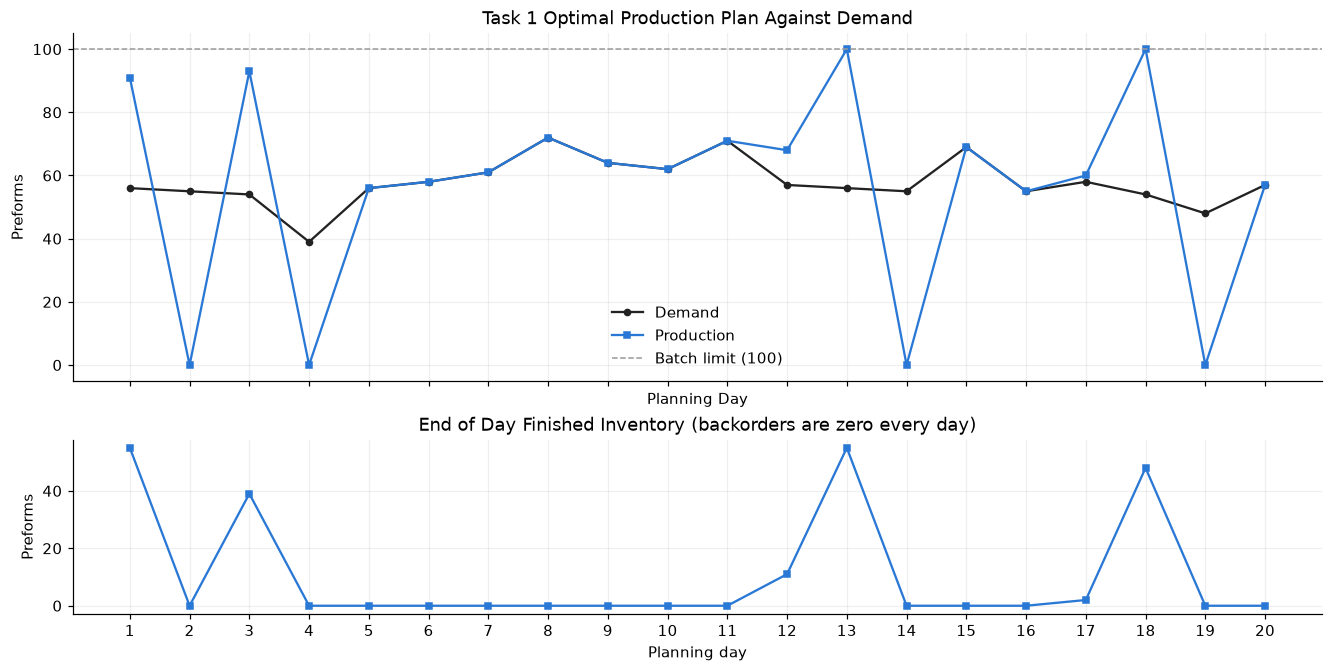

In [5]:
plot_production(task1_plan, "Task 1 Optimal Production Plan Against Demand")

### 1.b Verification: exact dynamic programme, uniqueness and lot-for-lot benchmark

In [6]:
def lot_sizing_dp(dem):
    """Exact DP over end-of-day net inventory (I - B); independent of the MILP solver."""
    total = sum(dem.values())
    lo, hi = -total, total + I0
    size = hi - lo + 1
    levels = np.arange(lo, hi + 1)
    cost = np.full(size, np.inf)
    cost[I0 - lo] = 0.0
    choices = []
    for t in DAYS:
        best = np.full(size, np.inf)
        arg = np.zeros(size, dtype=int)
        for x in range(M + 1):
            shift = x - dem[t]
            cand = np.full(size, np.inf)
            if shift >= 0:
                cand[shift:] = cost[:size - shift]
            else:
                cand[:size + shift] = cost[-shift:]
            cand = cand + (K if x > 0 else 0) + c * x
            better = cand < best
            best[better], arg[better] = cand[better], x
        cost = best + h * np.maximum(levels, 0) + b * np.maximum(-levels, 0)
        choices.append(arg)
    final = np.where(levels >= 0, cost, np.inf)          # B_20 = 0
    idx = int(np.argmin(final))
    value, plan = final[idx], {}
    for t in reversed(DAYS):
        plan[t] = int(choices[t - 1][idx])
        idx -= plan[t] - dem[t]
    return value, plan


dp_value, dp_plan = lot_sizing_dp(demand)

# Re-solve the MILP with the optimal setup pattern excluded (no-good cut)
pattern = dict(zip(DAYS, task1_plan["Setup"]))
alt_model = pulp.LpProblem("Task1_exclude_optimal_pattern", pulp.LpMinimize)
alt_vars, alt_terms = production_block(alt_model)
alt_model += pulp.lpSum(alt_terms.values())
alt_model += (pulp.lpSum(alt_vars["y"][t] for t in DAYS if pattern[t] == 1)
              - pulp.lpSum(alt_vars["y"][t] for t in DAYS if pattern[t] == 0)
              <= sum(pattern.values()) - 1), "exclude_optimal_pattern"
solve_model(alt_model, "Task 1: next-best setup pattern")
next_best = pulp.value(alt_model.objective)

# Lot-for-lot benchmark: produce exactly the net requirement every day
stock, lfl_x, lfl_end = I0, {}, []
for t in DAYS:
    lfl_x[t] = max(demand[t] - stock, 0)
    stock += lfl_x[t] - demand[t]
    lfl_end.append(stock)
lfl_cost = K * sum(v > 0 for v in lfl_x.values()) + c * sum(lfl_x.values()) + h * sum(lfl_end)

task1_verification = pd.DataFrame({
    "Check": ["MILP optimum (PuLP/CBC)", "Exact dynamic programme", "Same daily plan as MILP",
              "Next-best setup pattern (MILP with optimal pattern excluded)", "Lot-for-lot benchmark"],
    "Value": [f"${task1_total:,.2f}", f"${dp_value:,.2f}",
              str(all(dp_plan[t] == task1_plan.loc[t - 1, "Production"] for t in DAYS)),
              f"${next_best:,.2f}", f"${lfl_cost:,.2f}"]})
display(task1_verification)
assert abs(dp_value - task1_total) < 1e-6 and next_best > task1_total


,Check,Value
0,MILP optimum (PuLP/CBC),"$30,520.00"
1,Exact dynamic programme,"$30,520.00"
2,Same daily plan as MILP,True
3,Next-best setup pattern (MILP with optimal pat...,"$30,530.00"
4,Lot-for-lot benchmark,"$31,370.00"


## Task 2: Input-Supply Optimisation

### 2.a Daily input requirements

In [7]:
requirements = task1_plan[["Day", "Production"]].copy()
requirements["Quartz (kg)"] = 80 * requirements["Production"]
requirements["Quartz (t)"] = requirements["Quartz (kg)"] / 1000
requirements["Helium (m3)"] = aG * requirements["Production"]
requirements["Cumulative quartz (t)"] = requirements["Quartz (t)"].cumsum()
requirements["Cumulative helium (m3)"] = requirements["Helium (m3)"].cumsum()
show_table(requirements)
print(f"Horizon totals: quartz {requirements['Quartz (t)'].sum():.2f} t, of which {Q0:.0f} t is in stock | "
      f"helium {requirements['Helium (m3)'].sum():,.0f} m3, of which {G0:.0f} m3 is in stock")

Day,Production,Quartz (kg),Quartz (t),Helium (m3),Cumulative quartz (t),Cumulative helium (m3)
1,91,"7,280",7.28,182.00,7.28,182.00
2,0,0,0.00,0.00,7.28,182.00
3,93,"7,440",7.44,186.00,14.72,368.00
4,0,0,0.00,0.00,14.72,368.00
5,56,"4,480",4.48,112.00,19.20,480.00
6,58,"4,640",4.64,116.00,23.84,596.00
7,61,"4,880",4.88,122.00,28.72,718.00
8,72,"5,760",5.76,144.00,34.48,862.00
9,64,"5,120",5.12,128.00,39.60,990.00
10,62,"4,960",4.96,124.00,44.56,"1,114.00"


Horizon totals: quartz 90.96 t, of which 5 t is in stock | helium 2,274 m3, of which 160 m3 is in stock


### 2.c Recommended supply plan

In [8]:
task2_model = pulp.LpProblem("Task2_fixed_production_supply", pulp.LpMinimize)
fixed_x = dict(zip(DAYS, task1_plan["Production"]))
seq_supply, seq_supply_terms = supply_block(task2_model, fixed_x)
task2_model += pulp.lpSum(seq_supply_terms.values())
task2_run = solve_model(task2_model, "Task 2: supply for fixed plan")
seq_plan = attach_supply(task1_plan, seq_supply)
task2_costs = {name: pulp.value(term) for name, term in seq_supply_terms.items()}
task2_total = sum(task2_costs.values())

required_q = (requirements["Cumulative quartz (t)"] - Q0) / requirements["Day"]
binding_day = int(requirements.loc[required_q.idxmax(), "Day"])
assert abs(required_q.max() - seq_supply["q"].value()) < 1e-6

plan_output = seq_plan[[
    "Day", "Production", "Quartz delivery (t)", "Quartz end (t)",
    "Helium arrival (m3)", "Helium end (m3)"
]].rename(columns={
    "Quartz delivery (t)": "Quartz Delivery (t)",
    "Quartz end (t)": "Quartz End Inventory (t)",
    "Helium arrival (m3)": "Helium Arrived (m³)",
    "Helium end (m3)": "Helium End Inventory (m³)"
})

# Format tonne columns to 3 decimal places (Production stays an integer)
for col in ["Quartz Delivery (t)", "Quartz End Inventory (t)"]:
    plan_output[col] = plan_output[col].map(lambda x: f"{x:.3f}")

# Format m³ columns to 0 decimal places
for col in ["Helium Arrived (m³)", "Helium End Inventory (m³)"]:
    plan_output[col] = plan_output[col].map(lambda x: f"{x:.0f}")

show_table(plan_output)
print("Helium orders: placed on the morning of day t-1, arriving on the morning of day t")
show_table(helium_schedule(seq_plan), decimals=0)
print(f"Binding day for the constant quartz rate: day {binding_day}")

Day,Production,Quartz Delivery (t),Quartz End Inventory (t),Helium Arrived (m³),Helium End Inventory (m³)
1,91,4.522,2.242,22,0
2,0,4.522,6.764,0,0
3,93,4.522,3.847,186,0
4,0,4.522,8.369,0,0
5,56,4.522,8.411,112,0
6,58,4.522,8.293,116,0
7,61,4.522,7.936,122,0
8,72,4.522,6.698,144,0
9,64,4.522,6.100,128,0
10,62,4.522,5.662,124,0


Helium orders: placed on the morning of day t-1, arriving on the morning of day t


Placed (morning of day),Arrives (morning of day),Order (m3),Use on arrival day (m3),End stock on arrival day (m3)
0,1,22,182,0
1,2,0,0,0
2,3,186,186,0
3,4,0,0,0
4,5,112,112,0
5,6,116,116,0
6,7,122,122,0
7,8,144,144,0
8,9,128,128,0
9,10,124,124,0


Binding day for the constant quartz rate: day 18


In [9]:
input_holding = task2_costs["Quartz holding"] + task2_costs["Helium holding"]
conversion = task2_costs["Quartz conversion"] + task2_costs["Helium conversion"]

cost_output = pd.DataFrame([
    ["Quartz procurement", task2_costs["Quartz procurement"], 0, 0],
    ["Helium procurement", task2_costs["Helium procurement"], 0, 0],
    ["Input holding", input_holding, 0, 0],
    ["Conversion", conversion, 0, 0],
    ["Total", task2_total, task1_total, task2_total + task1_total],
], columns=["Cost category", "Input supply", "Production plan", "Combined"])

show_table(cost_output, decimals=2)

Cost category,Input supply,Production plan,Combined
Quartz procurement,"31,655.56",0.00,0.00
Helium procurement,"1,057,000.00",0.00,0.00
Input holding,48.51,0.00,0.00
Conversion,"9,664.50",0.00,0.00
Total,"1,098,368.57","30,520.00","1,128,888.57"


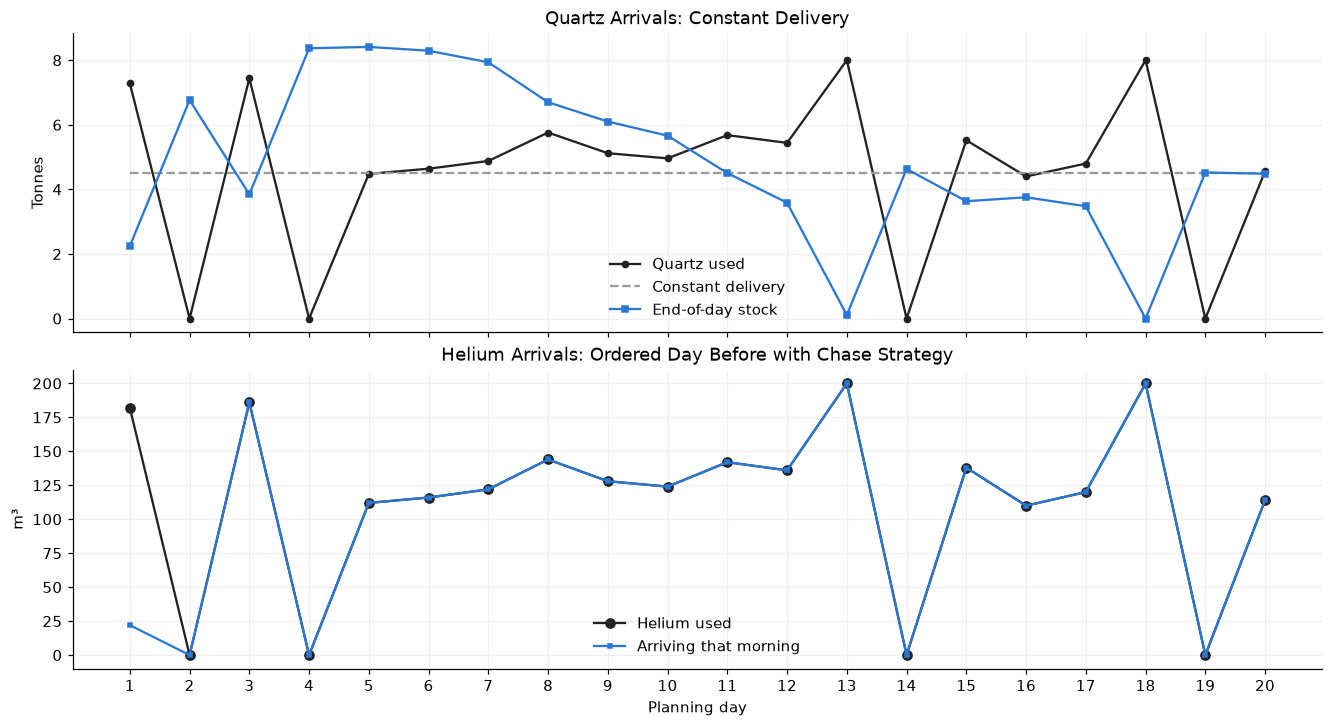

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, layout="constrained")
ax[0].plot(DAYS, seq_plan["Quartz use (t)"], color=INK, lw=1.5, marker="o", ms=4, label="Quartz used")
ax[0].plot(DAYS, seq_plan["Quartz delivery (t)"], color=COMPARE_COLOR, lw=1.5, ls="--", label="Constant delivery")
ax[0].plot(DAYS, seq_plan["Quartz end (t)"], color=MAIN_COLOR, lw=1.5, marker="s", ms=4, label="End-of-day stock")
ax[0].set(ylabel="Tonnes", title="Quartz Arrivals: Constant Delivery")
ax[0].legend()
ax[1].plot(DAYS, seq_plan["Helium use (m3)"], color=INK, lw=1.5, marker="o", ms=6, label="Helium used")
ax[1].plot(DAYS, seq_plan["Helium arrival (m3)"], color=MAIN_COLOR, lw=1.5, marker="s", ms=3, label="Arriving that morning")
ax[1].set(xlabel="Planning day", ylabel="m³", xticks=DAYS,
          title="Helium Arrivals: Ordered Day Before with Chase Strategy")
ax[1].legend()
plt.show()

## Task 3: Joint model 

The joint model combines the Task 1 and Task 2 models. Production $x_t$ is now a **decision variable** in the input balances, so timing can respond to the supply rules. The variables are $x_t,y_t,I_t,B_t,q,H_s,Q_t,G_t$, as defined in 1.a and 2.b.

### 3.b Joint optimal plan

In [11]:
joint_model = pulp.LpProblem("Task3_joint", pulp.LpMinimize)
joint_prod, joint_production_terms = production_block(joint_model)
joint_supply, joint_supply_terms = supply_block(joint_model, joint_prod["x"])
joint_terms = {**joint_production_terms, **joint_supply_terms}
joint_model += pulp.lpSum(joint_terms.values())
joint_run = solve_model(joint_model, "Task 3: joint")
joint_plan = attach_supply(production_table(joint_prod), joint_supply)
joint_costs = {name: pulp.value(term) for name, term in joint_terms.items()}
joint_total = sum(joint_costs.values())

print(f"Joint cost: ${joint_total:,.2f} | constant quartz delivery: {joint_supply['q'].value():.6f} t/day")
print("Setup days:", joint_plan.loc[joint_plan["Setup"] == 1, "Day"].tolist())
print("Production and finished balances (preforms)")
show_table(joint_plan[["Day", "Demand", "Production", "Setup", "Finished end", "Backorders end"]], decimals=0)
print("Quartz plan")
show_table(joint_plan[["Day", "Production", "Quartz delivery (t)", "Quartz use (t)", "Quartz end (t)"]], decimals=3)
print("Helium plan")
show_table(helium_schedule(joint_plan), decimals=0)

Joint cost: $1,127,637.48 | constant quartz delivery: 4.308889 t/day
Setup days: [1, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Production and finished balances (preforms)


Day,Demand,Production,Setup,Finished end,Backorders end
1,56,91,1,55,0
2,55,0,0,0,0
3,54,93,1,39,0
4,39,0,0,0,0
5,56,56,1,0,0
6,58,58,1,0,0
7,61,61,1,0,0
8,72,72,1,0,0
9,64,64,1,0,0
10,62,62,1,0,0


Quartz plan


Day,Production,Quartz delivery (t),Quartz use (t),Quartz end (t)
1,91,4.309,7.280,2.029
2,0,4.309,0.000,6.338
3,93,4.309,7.440,3.207
4,0,4.309,0.000,7.516
5,56,4.309,4.480,7.344
6,58,4.309,4.640,7.013
7,61,4.309,4.880,6.442
8,72,4.309,5.760,4.991
9,64,4.309,5.120,4.180
10,62,4.309,4.960,3.529


Helium plan


Placed (morning of day),Arrives (morning of day),Order (m3),Use on arrival day (m3),End stock on arrival day (m3)
0,1,22,182,0
1,2,0,0,0
2,3,186,186,0
3,4,0,0,0
4,5,112,112,0
5,6,116,116,0
6,7,122,122,0
7,8,144,144,0
8,9,128,128,0
9,10,124,124,0


In [12]:
COST_GROUPS = {"Setup": "Production", "Variable production": "Production", "Finished holding": "Holding",
               "Quartz holding": "Holding", "Helium holding": "Holding", "Backorder": "Backorder",
               "Quartz procurement": "Procurement", "Helium procurement": "Procurement",
               "Quartz conversion": "Conversion", "Helium conversion": "Conversion"}

joint_cost_table = pd.DataFrame({"Category": [COST_GROUPS[k] for k in joint_costs],
                                 "Cost component": list(joint_costs), "Joint ($)": list(joint_costs.values())})
joint_cost_table["Share (%)"] = 100 * joint_cost_table["Joint ($)"] / joint_total
joint_cost_table = joint_cost_table.sort_values("Category", key=lambda s: s.map(
    {"Production": 0, "Holding": 1, "Backorder": 2, "Procurement": 3, "Conversion": 4}), kind="stable")
show_table(joint_cost_table, money=True)

category_totals = joint_cost_table.groupby("Category", sort=False)[["Joint ($)", "Share (%)"]].sum().reset_index()
category_totals.loc[len(category_totals)] = ["TOTAL", joint_total, 100.0]
show_table(category_totals, money=True)

Category,Cost component,Joint ($),Share (%)
Production,Setup,"18,000.00",1.60
Production,Variable production,"11,370.00",1.01
Holding,Finished holding,"1,410.00",0.13
Holding,Quartz holding,30.75,0.00
Holding,Helium holding,0.00,0.00
Backorder,Backorder,0.00,0.00
Procurement,Quartz procurement,"30,162.22",2.67
Procurement,Helium procurement,"1,057,000.00",93.74
Conversion,Quartz conversion,"3,979.50",0.35
Conversion,Helium conversion,"5,685.00",0.50


Category,Joint ($),Share (%)
Production,"29,370.00",2.60
Holding,"1,440.75",0.13
Backorder,0.00,0.00
Procurement,"1,087,162.22",96.41
Conversion,"9,664.50",0.86
TOTAL,"1,127,637.48",100.00


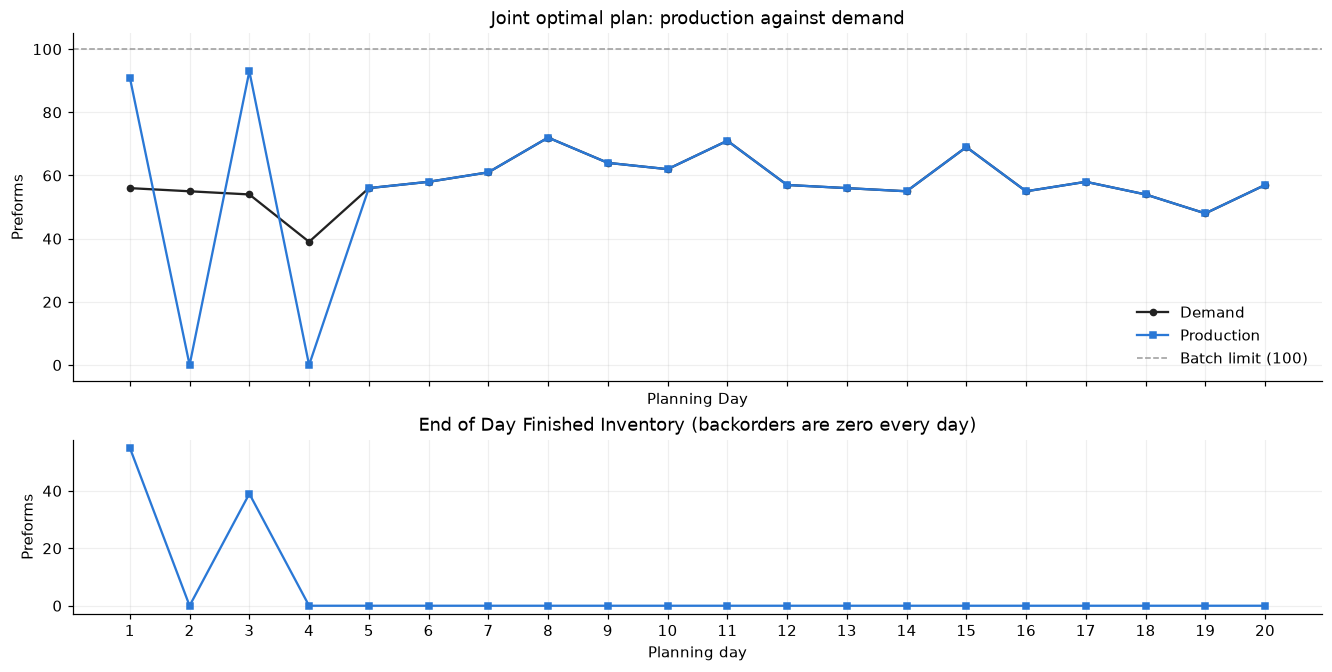

In [13]:
plot_production(joint_plan, "Joint optimal plan: production against demand")

### 3.c Sequential versus joint

In [14]:
seq_costs = {**task1_costs, **task2_costs}
seq_total = sum(seq_costs.values())
saving = seq_total - joint_total
print(f"Task 1 production cost:  ${task1_total:>14,.2f}")
print(f"Task 2 input cost:       ${task2_total:>14,.2f}")
print(f"Sequential total:        ${seq_total:>14,.2f}")
print(f"Joint total:             ${joint_total:>14,.2f}")
print(f"Joint saving:            ${saving:>14,.2f} ({100 * saving / seq_total:.2f}%)")

comparison = pd.DataFrame({"Sequential ($)": seq_costs, "Joint ($)": joint_costs})
comparison["Saving: sequential - joint ($)"] = comparison["Sequential ($)"] - comparison["Joint ($)"]
comparison.loc["TOTAL"] = comparison.sum()
show_table(comparison.rename_axis("Cost component").reset_index(), money=True)


def measures(plan):
    return [plan["Production"].sum(), plan["Setup"].sum(), plan["Finished end"].sum(), plan["Finished end"].max(),
            plan["Finished end"].iloc[-1], plan["Backorders end"].sum(), plan["Quartz delivery (t)"].iloc[0],
            plan["Quartz delivery (t)"].sum(), plan["Quartz end (t)"].sum(), plan["Quartz end (t)"].iloc[-1],
            plan["Helium arrival (m3)"].sum(), plan["Helium arrival (m3)"].max(), plan["Helium end (m3)"].sum()]


operating = pd.DataFrame({
    "Measure": ["Total production", "Setups", "Cumulative finished inventory", "Peak finished inventory",
                "Final finished inventory", "Cumulative backorders", "Daily quartz delivery", "Total quartz purchased",
                "Cumulative quartz inventory", "Final quartz inventory", "Total helium purchased",
                "Largest helium arrival", "Cumulative helium inventory"],
    "Unit": ["preforms", "batches", "preform-days", "preforms", "preforms", "preform-days", "t/day", "t",
             "t-days", "t", "m³", "m³", "m³-days"],
    "Sequential": measures(seq_plan), "Joint": measures(joint_plan)})
show_table(operating, decimals=3)

Task 1 production cost:  $     30,520.00
Task 2 input cost:       $  1,098,368.57
Sequential total:        $  1,128,888.57
Joint total:             $  1,127,637.48
Joint saving:            $      1,251.09 (0.11%)


Cost component,Sequential ($),Joint ($),Saving: sequential - joint ($)
Setup,"16,000.00","18,000.00","-2,000.00"
Variable production,"11,370.00","11,370.00",0.00
Finished holding,"3,150.00","1,410.00","1,740.00"
Backorder,0.00,0.00,0.00
Quartz procurement,"31,655.56","30,162.22","1,493.33"
Helium procurement,"1,057,000.00","1,057,000.00",0.00
Quartz holding,48.51,30.75,17.76
Helium holding,0.00,0.00,0.00
Quartz conversion,"3,979.50","3,979.50",0.00
Helium conversion,"5,685.00","5,685.00",0.00


Measure,Unit,Sequential,Joint
Total production,preforms,"1,137.000","1,137.000"
Setups,batches,16.000,18.000
Cumulative finished inventory,preform-days,210.000,94.000
Peak finished inventory,preforms,55.000,55.000
Final finished inventory,preforms,0.000,0.000
Cumulative backorders,preform-days,0.000,0.000
Daily quartz delivery,t/day,4.522,4.309
Total quartz purchased,t,90.444,86.178
Cumulative quartz inventory,t-days,97.027,61.507
Final quartz inventory,t,4.484,0.218


In [15]:
daily_comparison = pd.DataFrame({"Day": DAYS, "Demand": seq_plan["Demand"],
    "Production: seq": seq_plan["Production"], "Production: joint": joint_plan["Production"],
    "Finished end: seq": seq_plan["Finished end"], "Finished end: joint": joint_plan["Finished end"],
    "Quartz end: seq (t)": seq_plan["Quartz end (t)"], "Quartz end: joint (t)": joint_plan["Quartz end (t)"],
    "Helium arrival: seq (m3)": seq_plan["Helium arrival (m3)"], "Helium arrival: joint (m3)": joint_plan["Helium arrival (m3)"]})
show_table(daily_comparison, decimals=3)

changed = seq_plan["Production"] != joint_plan["Production"]
print("Days on which production differs (and the helium orders placed the morning before):")
show_table(daily_comparison.loc[changed, ["Day", "Production: seq", "Production: joint",
                                          "Helium arrival: seq (m3)", "Helium arrival: joint (m3)"]], decimals=0)

Day,Demand,Production: seq,Production: joint,Finished end: seq,Finished end: joint,Quartz end: seq (t),Quartz end: joint (t),Helium arrival: seq (m3),Helium arrival: joint (m3)
1,56,91,91,55,55,2.242,2.029,22.000,22.000
2,55,0,0,0,0,6.764,6.338,0.000,0.000
3,54,93,93,39,39,3.847,3.207,186.000,186.000
4,39,0,0,0,0,8.369,7.516,0.000,0.000
5,56,56,56,0,0,8.411,7.344,112.000,112.000
6,58,58,58,0,0,8.293,7.013,116.000,116.000
7,61,61,61,0,0,7.936,6.442,122.000,122.000
8,72,72,72,0,0,6.698,4.991,144.000,144.000
9,64,64,64,0,0,6.100,4.180,128.000,128.000
10,62,62,62,0,0,5.662,3.529,124.000,124.000


Days on which production differs (and the helium orders placed the morning before):


Day,Production: seq,Production: joint,Helium arrival: seq (m3),Helium arrival: joint (m3)
12,68,57,136,114
13,100,56,200,112
14,0,55,0,110
17,60,58,120,116
18,100,54,200,108
19,0,48,0,96


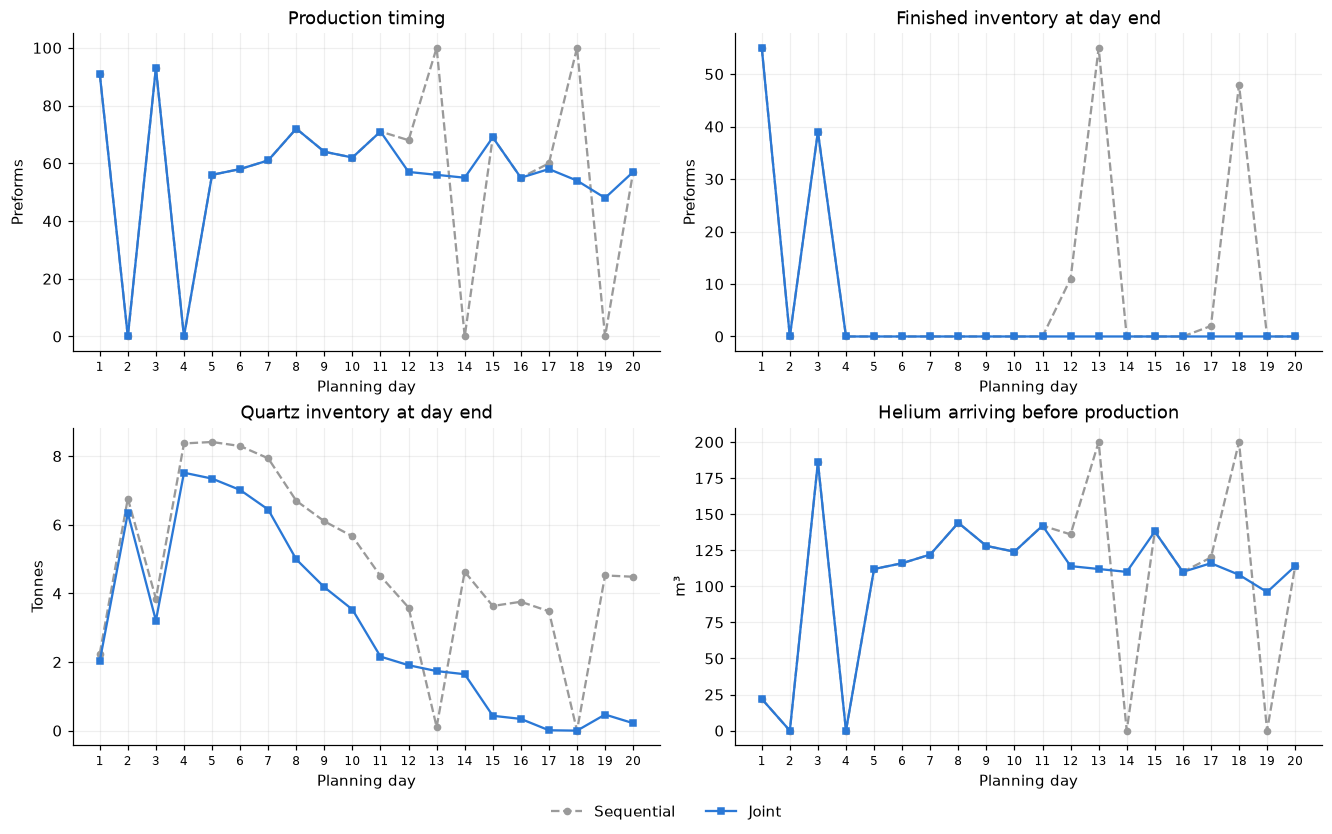

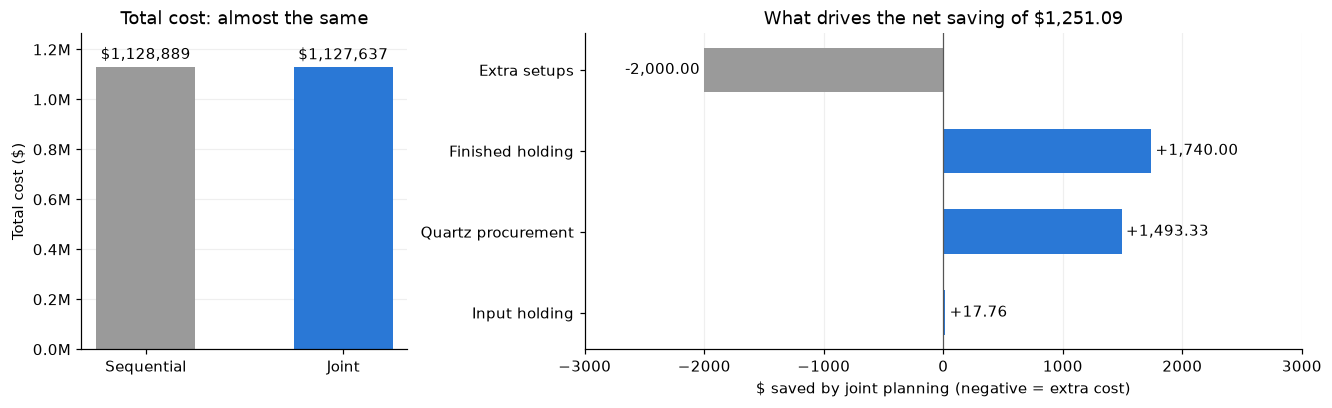

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
series = [("Production", "Preforms", "Production timing"),
          ("Finished end", "Preforms", "Finished inventory at day end"),
          ("Quartz end (t)", "Tonnes", "Quartz inventory at day end"),
          ("Helium arrival (m3)", "m³", "Helium arriving before production")]
for ax, (column, unit, title) in zip(axes.flat, series):
    ax.plot(DAYS, seq_plan[column], color=COMPARE_COLOR, lw=1.5, ls="--", marker="o", ms=4, label="Sequential")
    ax.plot(DAYS, joint_plan[column], color=MAIN_COLOR, lw=1.5, marker="s", ms=4, label="Joint")
    ax.set(title=title, xlabel="Planning day", ylabel=unit, xticks=DAYS)
    ax.tick_params(axis="x", labelsize=8)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
plt.show()

components = ["Extra setups", "Finished holding", "Quartz procurement", "Input holding"]
contributions = [seq_costs["Setup"] - joint_costs["Setup"],
                 seq_costs["Finished holding"] - joint_costs["Finished holding"],
                 seq_costs["Quartz procurement"] - joint_costs["Quartz procurement"],
                 sum(seq_costs[k] - joint_costs[k] for k in ["Quartz holding", "Helium holding"])]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained", gridspec_kw={"width_ratios": [1, 2.2]})
bars = ax[0].bar(["Sequential", "Joint"], [seq_total, joint_total], color=[COMPARE_COLOR, MAIN_COLOR], width=.5)
ax[0].bar_label(bars, labels=[f"${seq_total:,.0f}", f"${joint_total:,.0f}"], padding=3)
ax[0].set(ylim=(0, seq_total * 1.12), ylabel="Total cost ($)", title="Total cost: almost the same")
ax[0].yaxis.set_major_formatter(lambda v, _: f"{v / 1e6:.1f}M")
ax[0].grid(axis="x", visible=False)
ax[1].barh(components, contributions, color=[COMPARE_COLOR if v < 0 else MAIN_COLOR for v in contributions], height=.55)
ax[1].axvline(0, color="#555555", linewidth=.8)
for i, value in enumerate(contributions):
    ax[1].text(value + (35 if value >= 0 else -35), i, f"{value:+,.2f}", va="center",
               ha="left" if value >= 0 else "right")
span = max(abs(v) for v in contributions) * 1.5
ax[1].set(xlim=(-span, span), xlabel="$ saved by joint planning (negative = extra cost)",
          title=f"What drives the net saving of ${saving:,.2f}")
ax[1].invert_yaxis()
ax[1].grid(axis="y", visible=False)
plt.show()

### 3.c Controllable cost and robustness of the two plans

In [17]:
CONTROLLABLE = ["Setup", "Finished holding", "Backorder", "Quartz procurement", "Quartz holding", "Helium holding"]
ctrl_seq = sum(seq_costs[k] for k in CONTROLLABLE)
ctrl_joint = sum(joint_costs[k] for k in CONTROLLABLE)
print(f"Plan-dependent (controllable) cost: sequential ${ctrl_seq:,.2f} | joint ${ctrl_joint:,.2f} | "
      f"saving ${ctrl_seq - ctrl_joint:,.2f} ({100 * (ctrl_seq - ctrl_joint) / ctrl_seq:.2f}%)")
print("Invariant cost (helium procurement, conversion, variable production): "
      f"${seq_total - ctrl_seq:,.2f} = {100 * (seq_total - ctrl_seq) / seq_total:.1f}% of the sequential total")


def variant(dem=None, q_fixed=None, q_buffer=0.0, g_buffer=0.0, fix_x=None):
    """Joint model with optional safety stocks (days 1-19), fixed quartz rate or fixed production."""
    m = pulp.LpProblem("variant", pulp.LpMinimize)
    p, pt = production_block(m, dem)
    s, st = supply_block(m, p["x"])
    for t in DAYS[:-1]:
        m += s["Q"][t] >= q_buffer
        m += s["G"][t] >= g_buffer
    if q_fixed is not None:
        m += s["q"] == q_fixed
    if fix_x is not None:
        for t in DAYS:
            m += p["x"][t] == fix_x[t]
    m += pulp.lpSum({**pt, **st}.values())
    m.solve(pulp.PULP_CBC_CMD(msg=False, gapRel=0, gapAbs=0, threads=1))
    feasible = m.status == pulp.LpStatusOptimal
    return (pulp.value(m.objective) if feasible else None), (s["q"].value() if feasible else None), feasible


rows = []
for qb in [0.5, 1.0, 2.0]:
    j_cost, j_q, _ = variant(q_buffer=qb)
    s_cost, s_q, _ = variant(q_buffer=qb, fix_x=fixed_x)
    rows.append([f"Quartz safety stock {qb:.1f} t (days 1-19)", s_cost, s_q, j_cost, j_q])
for gb in [50, 100]:
    j_cost, j_q, _ = variant(g_buffer=gb)
    s_cost, s_q, _ = variant(g_buffer=gb, fix_x=fixed_x)
    rows.append([f"Helium safety stock {gb} m3 (days 1-19)", s_cost, s_q, j_cost, j_q])
robustness = pd.DataFrame(rows, columns=["Scenario", "Sequential cost ($)", "Sequential q (t/day)",
                                         "Joint cost ($)", "Joint q (t/day)"])
robustness["Joint cheaper than unbuffered sequential by ($)"] = seq_total - robustness["Joint cost ($)"]
show_table(robustness, decimals=4)


def max_extra_day20(q_rate):
    """Largest extra day-20 demand that can still be met (B_20 = 0) once the quartz rate is locked."""
    k = 0
    while True:
        dem = dict(demand)
        dem[20] += k + 1
        if not variant(dem=dem, q_fixed=q_rate)[2]:
            return k
        k += 1


absorb_seq = max_extra_day20(seq_supply["q"].value())
absorb_joint = max_extra_day20(joint_supply["q"].value())
print(f"Extra day-20 demand absorbable after the quartz rate is locked: "
      f"sequential {absorb_seq} preforms | joint {absorb_joint} preforms")


Plan-dependent (controllable) cost: sequential $50,854.07 | joint $49,602.98 | saving $1,251.09 (2.46%)
Invariant cost (helium procurement, conversion, variable production): $1,078,034.50 = 95.5% of the sequential total


Scenario,Sequential cost ($),Sequential q (t/day),Joint cost ($),Joint q (t/day),Joint cheaper than unbuffered sequential by ($)
Quartz safety stock 0.5 t (days 1-19),"1,129,102.3262",4.5523,"1,127,841.8026",4.3376,"1,046.7661"
Quartz safety stock 1.0 t (days 1-19),"1,129,375.5952",4.5908,"1,128,050.7728",4.3671,837.7960
Quartz safety stock 2.0 t (days 1-19),"1,129,922.1338",4.6677,"1,128,468.7144",4.4259,419.8543
Helium safety stock 50 m3 (days 1-19),"1,129,838.5687",4.5222,"1,128,587.4756",4.3089,301.0931
Helium safety stock 100 m3 (days 1-19),"1,130,788.5687",4.5222,"1,129,537.4756",4.3089,-648.9069


Extra day-20 demand absorbable after the quartz rate is locked: sequential 56 preforms | joint 2 preforms


### 3.d Recommendation

In [18]:
show_table(pd.DataFrame([task1_run, task2_run, joint_run]), decimals=3)

Model,Status,Variables,Constraints,Seconds,Objective ($)
Task 1: production only,Optimal,82,43,0.602,"30,520.000"
Task 2: supply for fixed plan,Optimal,63,42,0.020,"1,098,368.569"
Task 3: joint,Optimal,145,85,0.091,"1,127,637.476"


## Task 4: ML Demand Prediction
### 4.a Baselines, ML models and test metrics

In [19]:
TARGET = "synthetic_demand_preforms"
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SEED = 3340

print(hist.shape, hist["date"].min().date(), "to", hist["date"].max().date(),
      "| missing values:", int(hist.isna().sum().sum()))
print("\nMean demand by weekday")
print(hist.groupby("day_of_week")[TARGET].mean().reindex(WEEKDAYS).round(1).to_string())
print("\nDemand by large-project flag")
print(hist.groupby("large_customer_project")[TARGET].agg(["mean", "count"]).round(1).to_string())
print("\ncorr(demand, quote_request_index):", round(hist[TARGET].corr(hist["quote_request_index"]), 3))
print("autocorrelation lag1 / lag7:", round(hist[TARGET].autocorr(1), 3), "/", round(hist[TARGET].autocorr(7), 3))

(398, 9) 2025-07-01 to 2026-08-02 | missing values: 0

Mean demand by weekday
day_of_week
Mon    55.5
Tue    54.0
Wed    51.1
Thu    50.6
Fri    47.9
Sat    44.8
Sun    44.1

Demand by large-project flag
                        mean  count
large_customer_project             
0                       47.0    329
1                       62.4     69

corr(demand, quote_request_index): 0.537
autocorrelation lag1 / lag7: 0.635 / 0.606


In [20]:
def build_features(df, target):
    # Features for day t use only demand up to day t-1, plus the calendar and the
    # two indicators the brief says are known before the prediction is made.
    f = pd.DataFrame(index=df.index)
    f["lag1"] = df[target].shift(1)
    f["lag2"] = df[target].shift(2)
    f["lag7"] = df[target].shift(7)
    f["roll7"] = df[target].shift(1).rolling(7).mean()      # mean of t-7..t-1, excludes day t
    f["large_project"] = df["large_customer_project"]
    f["quote_idx"] = df["quote_request_index"]
    f["quote_idx_lag1"] = df["quote_request_index"].shift(1)
    for weekday in WEEKDAYS[1:]:                             # Monday is the reference day
        f["dow_" + weekday] = (df["day_of_week"] == weekday).astype(int)
    return f


KEEP = ["date", "day_of_week", "large_customer_project", "quote_request_index", TARGET]
series = hist[KEEP].copy()
features = build_features(series, TARGET)
usable = features.notna().all(axis=1)                        # drops the first 7 days (no lag-7)
series, features = series[usable].reset_index(drop=True), features[usable].reset_index(drop=True)

n_train = int(round(0.8 * len(series)))                      # first 80% train, last 20% test
train_idx, test_idx = np.arange(n_train), np.arange(n_train, len(series))
X_train, y_train = features.iloc[train_idx], series[TARGET].iloc[train_idx]
X_test, y_test = features.iloc[test_idx], series[TARGET].iloc[test_idx]
test_dates = series["date"].iloc[test_idx]
print(f"usable rows {len(series)} | train {len(train_idx)} ({series['date'].iloc[0].date()} to {series['date'].iloc[n_train - 1].date()})"
      f" | test {len(test_idx)} ({test_dates.iloc[0].date()} to {test_dates.iloc[-1].date()})")


def forecast_metrics(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    return dict(MAE=mean_absolute_error(actual, predicted),
                RMSE=float(np.sqrt(mean_squared_error(actual, predicted))),
                MAPE_pct=100 * np.mean(np.abs(actual - predicted) / actual),
                Bias=np.mean(predicted - actual))    # predicted minus actual


predictions = {
    "Naive (yesterday)": X_test["lag1"].values,
    "Seasonal naive (same weekday last week)": X_test["lag7"].values,
    "7-day moving average": X_test["roll7"].values,
}

# Ridge penalty chosen by expanding-window cross-validation inside the training block only
best_alpha, best_cv = None, np.inf
for alpha in [0.01, 0.1, 1, 3, 10, 30, 100]:
    fold_errors = []
    for fit_idx, val_idx in TimeSeriesSplit(n_splits=5).split(X_train):
        cv_model = Ridge(alpha=alpha).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        fold_errors.append(mean_absolute_error(y_train.iloc[val_idx], cv_model.predict(X_train.iloc[val_idx])))
    if np.mean(fold_errors) < best_cv:
        best_alpha, best_cv = alpha, np.mean(fold_errors)
print("Ridge alpha chosen by time-series CV on train:", best_alpha)

ols = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=best_alpha).fit(X_train, y_train)
gbr = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                subsample=0.8, random_state=SEED).fit(X_train, y_train)
predictions["Linear regression (OLS)"] = ols.predict(X_test)
predictions[f"Ridge regression (alpha={best_alpha})"] = ridge.predict(X_test)
predictions["Gradient boosting (depth 2)"] = gbr.predict(X_test)

print("\nOne-day-ahead test metrics (Bias is predicted minus actual; negative = under-forecasting)")
display(pd.DataFrame({name: forecast_metrics(y_test, p) for name, p in predictions.items()}).T.round(2))

usable rows 391 | train 313 (2025-07-08 to 2026-05-16) | test 78 (2026-05-17 to 2026-08-02)
Ridge alpha chosen by time-series CV on train: 0.01

One-day-ahead test metrics (Bias is predicted minus actual; negative = under-forecasting)


,MAE,RMSE,MAPE_pct,Bias
Naive (yesterday),7.13,8.78,13.00,0.41
Seasonal naive (same weekday last week),7.74,9.62,13.92,0.79
7-day moving average,6.10,7.56,11.29,0.76
Linear regression (OLS),4.72,5.78,8.34,-0.99
Ridge regression (alpha=0.01),4.71,5.78,8.34,-0.99
Gradient boosting (depth 2),5.29,6.63,9.40,-1.46


In [21]:
coefficients = pd.Series(ols.coef_, index=X_train.columns).round(3)
coefficients["intercept"] = round(ols.intercept_, 3)
print("OLS coefficients")
print(coefficients.to_string())

# Paired block bootstrap (7-day blocks) of the MAE gain of OLS over the naive baseline
rng = np.random.default_rng(SEED)
mae_gain = np.abs(y_test.values - predictions["Naive (yesterday)"]) - np.abs(y_test.values - predictions["Linear regression (OLS)"])
blocks = [mae_gain[i:i + 7] for i in range(0, len(mae_gain), 7)]
boot = [np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]).mean()
        for _ in range(5000)]
print("\nMAE gain of OLS over naive: %.2f, 95%% block-bootstrap CI [%.2f, %.2f]"
      % (mae_gain.mean(), *np.percentile(boot, [2.5, 97.5])))

OLS coefficients
lag1               0.231
lag2               0.095
lag7              -0.062
roll7              0.465
large_project      4.215
quote_idx          0.282
quote_idx_lag1    -0.192
dow_Tue           -5.039
dow_Wed           -8.479
dow_Thu           -8.762
dow_Fri          -10.840
dow_Sat          -13.075
dow_Sun          -13.519
intercept         16.069

MAE gain of OLS over naive: 2.41, 95% block-bootstrap CI [1.48, 3.32]


### 4.b Actual versus predicted demand

Last 14 test days (the full table is in test_table)


,date,day,actual,naive,ols,naive_error,ols_error
64,2026-07-20,Mon,51,47.0,57.2,4.0,-6.2
65,2026-07-21,Tue,62,51.0,52.8,11.0,9.2
66,2026-07-22,Wed,46,62.0,52.6,-16.0,-6.6
67,2026-07-23,Thu,63,46.0,49.0,17.0,14.0
68,2026-07-24,Fri,42,63.0,47.0,-21.0,-5.0
69,2026-07-25,Sat,52,42.0,46.2,10.0,5.8
70,2026-07-26,Sun,41,52.0,42.7,-11.0,-1.7
71,2026-07-27,Mon,56,41.0,56.2,15.0,-0.2
72,2026-07-28,Tue,57,56.0,54.1,1.0,2.9
73,2026-07-29,Wed,50,57.0,49.4,-7.0,0.6


Confirmed 20-day horizon (illustration only; not used for model selection)

,planning_day,date,actual_confirmed,naive,ols,ols_error
0,1,2026-08-03,56,34.0,51.2,4.8
1,2,2026-08-04,55,56.0,52.0,3.0
2,3,2026-08-05,54,55.0,48.9,5.1
3,4,2026-08-06,39,54.0,49.0,-10.0
4,5,2026-08-07,56,39.0,51.3,4.7
5,6,2026-08-08,58,56.0,50.7,7.3
6,7,2026-08-09,61,58.0,52.6,8.4
7,8,2026-08-10,72,61.0,66.4,5.6
8,9,2026-08-11,64,72.0,67.1,-3.1
9,10,2026-08-12,62,64.0,63.2,-1.2


OLS   (20 days): {'MAE': 5.42, 'RMSE': 6.22, 'MAPE_pct': 9.75, 'Bias': -0.71}
Naive (20 days): {'MAE': 7.85, 'RMSE': 10.04, 'MAPE_pct': 13.93, 'Bias': -1.15}


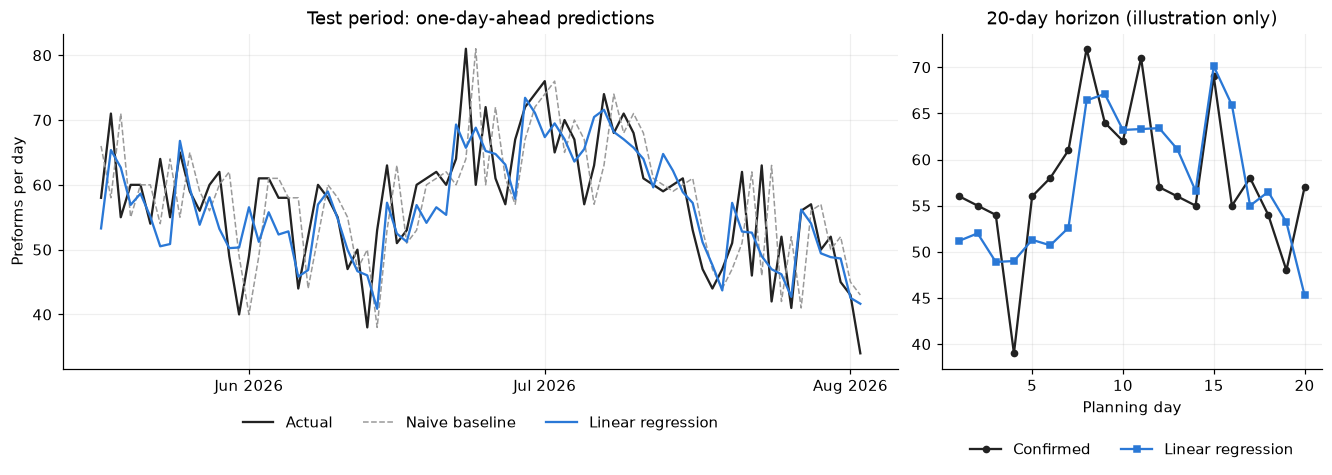

In [22]:
test_table = pd.DataFrame({
    "date": test_dates.dt.date.values,
    "day": series["day_of_week"].iloc[test_idx].values,
    "actual": y_test.values,
    "naive": predictions["Naive (yesterday)"],
    "ols": predictions["Linear regression (OLS)"].round(1),
})
test_table["naive_error"] = (test_table["actual"] - test_table["naive"]).round(1)
test_table["ols_error"] = (test_table["actual"] - test_table["ols"]).round(1)
print("Last 14 test days (the full table is in test_table)")
display(test_table.tail(14))

confirmed_rows = conf.rename(columns={"confirmed_demand_preforms": TARGET})[KEEP]
combined = pd.concat([hist[KEEP], confirmed_rows], ignore_index=True)
confirmed_features = build_features(combined, TARGET).iloc[-20:]
confirmed_pred = pd.DataFrame({
    "planning_day": conf["planning_day"].values,
    "date": conf["date"].dt.date.values,
    "actual_confirmed": conf["confirmed_demand_preforms"].values,
    "naive": confirmed_features["lag1"].values,
    "ols": ols.predict(confirmed_features[X_train.columns]).round(1),
})
confirmed_pred["ols_error"] = (confirmed_pred["actual_confirmed"] - confirmed_pred["ols"]).round(1)
print("Confirmed 20-day horizon (illustration only; not used for model selection)")
display(confirmed_pred)
print("OLS   (20 days):", {k: round(float(v), 2) for k, v in forecast_metrics(confirmed_pred["actual_confirmed"], confirmed_pred["ols"]).items()})
print("Naive (20 days):", {k: round(float(v), 2) for k, v in forecast_metrics(confirmed_pred["actual_confirmed"], confirmed_pred["naive"]).items()})

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained", gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(test_dates, y_test.values, color=INK, lw=1.5, label="Actual")
ax[0].plot(test_dates, predictions["Naive (yesterday)"], color=COMPARE_COLOR, lw=1, ls="--", label="Naive baseline")
ax[0].plot(test_dates, predictions["Linear regression (OLS)"], color=MAIN_COLOR, lw=1.5, label="Linear regression")
ax[0].set(title="Test period: one-day-ahead predictions", ylabel="Preforms per day")
ax[0].xaxis.set_major_locator(mdates.MonthLocator())
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax[1].plot(confirmed_pred["planning_day"], confirmed_pred["actual_confirmed"], color=INK, lw=1.5, marker="o", ms=4, label="Confirmed")
ax[1].plot(confirmed_pred["planning_day"], confirmed_pred["ols"], color=MAIN_COLOR, lw=1.5, marker="s", ms=4, label="Linear regression")
ax[1].set(title="20-day horizon (illustration only)", xlabel="Planning day")
ax[1].legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.show()

### 4.c Prediction error, uncertainty and planning

Target quantile tau = 0.870



,MAE,Pinball loss (tau=0.87),Coverage (share actual <= forecast),Avg shortfall (preforms/day),Avg excess (preforms/day),Cost of error ($/day)
Model,,,,,,
OLS mean forecast,4.716,2.722,0.436,2.851,1.865,313.071
OLS mean + buffer,6.694,1.264,0.859,0.529,6.165,145.408
Linear quantile regression,6.183,1.267,0.821,0.623,5.560,145.691
Gradient boosting (quantile loss),6.131,1.604,0.731,1.088,5.043,184.437


Median forecasts (typical-day accuracy)


,MAE,RMSE,Coverage (share actual <= forecast)
OLS mean forecast,4.716,5.781,0.436
Linear quantile regression (median),4.651,5.701,0.462
Gradient boosting (median),5.388,6.717,0.397


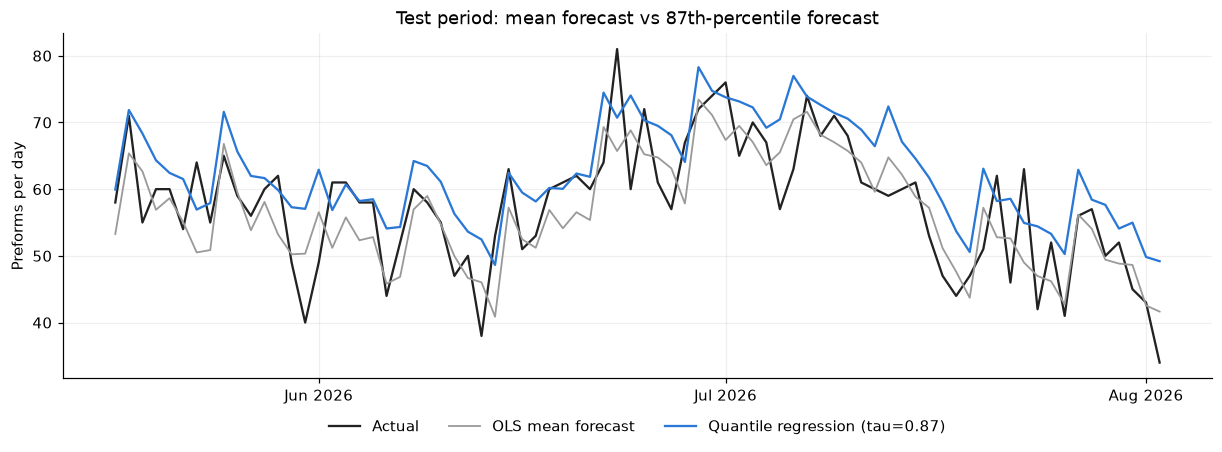

In [23]:
# Why: a backorder costs $100/unit/day and holding costs $15/unit/day, so the cost-minimising
# forecast is not the mean but the quantile tau = 100 / (100 + 15) = 0.87.
# Quantile models predict that quantile directly, instead of "mean forecast + a buffer".
BACK_COST, HOLD_COST = b, h
TAU = BACK_COST / (BACK_COST + HOLD_COST)
y_actual = y_test.to_numpy(float)

quantile_preds = {}
for tau in [0.50, TAU]:
    linear_q = QuantileRegressor(quantile=tau, alpha=0.0, solver="highs").fit(X_train, y_train)
    boosted_q = GradientBoostingRegressor(loss="quantile", alpha=tau, n_estimators=150, max_depth=2,
                                          learning_rate=0.05, subsample=0.8, random_state=SEED).fit(X_train, y_train)
    quantile_preds[("Linear quantile regression", tau)] = linear_q.predict(X_test)
    quantile_preds[("Gradient boosting (quantile loss)", tau)] = boosted_q.predict(X_test)

ols_mean = ols.predict(X_test)
train_sd = np.std(y_train.to_numpy(float) - ols.predict(X_train), ddof=1)
ols_buffer = ols_mean + norm.ppf(TAU) * train_sd


def quantile_row(name, predicted, tau):
    return {"Model": name,
            "MAE": mean_absolute_error(y_actual, predicted),
            f"Pinball loss (tau={tau:.2f})": mean_pinball_loss(y_actual, predicted, alpha=tau),
            "Coverage (share actual <= forecast)": np.mean(y_actual <= predicted),
            "Avg shortfall (preforms/day)": np.mean(np.maximum(y_actual - predicted, 0)),
            "Avg excess (preforms/day)": np.mean(np.maximum(predicted - y_actual, 0)),
            "Cost of error ($/day)": BACK_COST * np.mean(np.maximum(y_actual - predicted, 0))
                                     + HOLD_COST * np.mean(np.maximum(predicted - y_actual, 0))}


quantile_table = pd.DataFrame([
    quantile_row("OLS mean forecast", ols_mean, TAU),
    quantile_row("OLS mean + buffer", ols_buffer, TAU),
    quantile_row("Linear quantile regression", quantile_preds[("Linear quantile regression", TAU)], TAU),
    quantile_row("Gradient boosting (quantile loss)", quantile_preds[("Gradient boosting (quantile loss)", TAU)], TAU),
]).set_index("Model").round(3)
print(f"Target quantile tau = {TAU:.3f}\n")
display(quantile_table)

median_table = pd.DataFrame({name: {"MAE": mean_absolute_error(y_actual, p),
                                    "RMSE": np.sqrt(mean_squared_error(y_actual, p)),
                                    "Coverage (share actual <= forecast)": np.mean(y_actual <= p)}
    for name, p in {"OLS mean forecast": ols_mean,
                    "Linear quantile regression (median)": quantile_preds[("Linear quantile regression", 0.50)],
                    "Gradient boosting (median)": quantile_preds[("Gradient boosting (quantile loss)", 0.50)]}.items()}).T.round(3)
print("Median forecasts (typical-day accuracy)")
display(median_table)

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(test_dates, y_actual, color=INK, lw=1.5, label="Actual")
ax.plot(test_dates, ols_mean, color=COMPARE_COLOR, lw=1.2, label="OLS mean forecast")
ax.plot(test_dates, quantile_preds[("Linear quantile regression", TAU)], color=MAIN_COLOR, lw=1.5,
        label=f"Quantile regression (tau={TAU:.2f})")
ax.set(ylabel="Preforms per day", title="Test period: mean forecast vs 87th-percentile forecast")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.show()

In [24]:
def audit(plan, label):
    # Recompute the balances and every cost from the reported daily plan alone.
    net = I0 - B0 + (plan["Production"] - plan["Demand"]).cumsum()
    assert (plan["Finished end"] - plan["Backorders end"] == net).all(), label
    assert plan["Backorders end"].iloc[-1] == 0, label
    assert (plan["Production"] <= M * plan["Setup"]).all(), label
    q = plan["Quartz delivery (t)"].iloc[0]
    assert np.allclose(plan["Quartz delivery (t)"], q), label
    assert np.allclose(plan["Quartz end (t)"], Q0 + (q - aQ * plan["Production"]).cumsum(), atol=1e-6), label
    assert np.allclose(plan["Helium end (m3)"], G0 + (plan["Helium arrival (m3)"] - aG * plan["Production"]).cumsum(), atol=1e-6), label
    assert (plan["Quartz end (t)"] >= -1e-6).all() and (plan["Helium end (m3)"] >= -1e-6).all(), label
    return (K * plan["Setup"].sum() + c * plan["Production"].sum() + h * plan["Finished end"].sum()
            + b * plan["Backorders end"].sum() + 20 * pQ * q + pG * plan["Helium arrival (m3)"].sum()
            + hQ * plan["Quartz end (t)"].sum() + hG * plan["Helium end (m3)"].sum()
            + (vQ + vG) * plan["Production"].sum())


assert abs(audit(seq_plan, "sequential") - seq_total) < 0.01
assert abs(audit(joint_plan, "joint") - joint_total) < 0.01
assert abs(pulp.value(joint_model.objective) - joint_total) < 0.01

expected = {"Task 1 total": (task1_total, 30520.00), "Task 2 total": (task2_total, 1098368.57),
          "Sequential total": (seq_total, 1128888.57), "Joint total": (joint_total, 1127637.48),
          "Joint saving": (saving, 1251.09), "Sequential quartz rate": (seq_supply["q"].value(), 4.522222),
          "Joint quartz rate": (joint_supply["q"].value(), 4.308889),
          "Sequential setups": (seq_plan["Setup"].sum(), 16), "Joint setups": (joint_plan["Setup"].sum(), 18),
          "Sequential preform-days": (seq_plan["Finished end"].sum(), 210), "Joint preform-days": (joint_plan["Finished end"].sum(), 94),
          "Helium purchased": (joint_plan["Helium arrival (m3)"].sum(), 2114),
          "OLS test MAE": (forecast_metrics(y_test, predictions["Linear regression (OLS)"])["MAE"], 4.72),
          "Naive test MAE": (forecast_metrics(y_test, predictions["Naive (yesterday)"])["MAE"], 7.13),
          "OLS cost of error": (quantile_table.loc["OLS mean forecast", "Cost of error ($/day)"], 313.07),
          "Buffer cost of error": (quantile_table.loc["OLS mean + buffer", "Cost of error ($/day)"], 145.41),
          "Buffer MAE": (quantile_table.loc["OLS mean + buffer", "MAE"], 6.69)}
for name, (computed, stated) in expected.items():
    assert abs(computed - stated) < 0.01, f"{name}: computed {computed}, expected {stated}"
assert seq_plan["Backorders end"].sum() == joint_plan["Backorders end"].sum() == 0
print(f"All checks passed: 2 plans audited, {len(expected)} expected figures confirmed.")

All checks passed: 2 plans audited, 17 expected figures confirmed.


## Report figures (print size, 10-pt text)
The figures in the report are regenerated here at their printed width (6.25 in, no scaling) so that all text is at least 10 pt. They are saved to `final_report/figures/`.

In [25]:
FIG_DIR = Path("final_report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
W = 6.25
print_style = {"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "xtick.labelsize": 10,
               "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 110}
EVEN = list(range(2, 21, 2))

with plt.rc_context(print_style):
    # Figure 1: Task 1 plan
    fig, ax = plt.subplots(2, 1, figsize=(W, 4.0), sharex=True, layout="constrained",
                           gridspec_kw={"height_ratios": [1.7, 1]})
    ax[0].plot(DAYS, task1_plan["Demand"], color=INK, lw=1.4, marker="o", ms=3.5, label="Demand")
    ax[0].bar(DAYS, task1_plan["Production"], color=MAIN_COLOR, alpha=0.75, width=0.6, label="Production")
    ax[0].axhline(M, color=COMPARE_COLOR, ls="--", lw=1, label="Batch limit (100)")
    ax[0].set(ylabel="Preforms", ylim=(0, 115))
    ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.22))
    ax[1].bar(DAYS, task1_plan["Finished end"], color=MAIN_COLOR, width=0.6)
    ax[1].set(xlabel="Planning day", ylabel="End stock", xticks=EVEN)
    fig.savefig(FIG_DIR / "fig1_task1_plan.pdf"); plt.close(fig)

    # Figure 2: Task 2 supply plan
    fig, ax = plt.subplots(2, 1, figsize=(W, 4.2), sharex=True, layout="constrained")
    ax[0].plot(DAYS, seq_plan["Quartz use (t)"], color=INK, lw=1.4, marker="o", ms=3.5, label="Quartz used")
    ax[0].plot(DAYS, seq_plan["Quartz delivery (t)"], color=COMPARE_COLOR, lw=1.4, ls="--", label="Constant delivery")
    ax[0].plot(DAYS, seq_plan["Quartz end (t)"], color=MAIN_COLOR, lw=1.4, marker="s", ms=3.5, label="End-of-day stock")
    ax[0].set(ylabel="Tonnes", ylim=(0, 11.5), title="Quartz: constant delivery of %.3f t/day" % seq_supply["q"].value())
    ax[0].legend(ncol=3, loc="upper center")
    ax[1].bar(DAYS, seq_plan["Helium arrival (m3)"], color=MAIN_COLOR, alpha=0.75, width=0.6,
              label="Arrival (ordered previous morning)")
    ax[1].plot(DAYS, seq_plan["Helium use (m3)"], color=INK, lw=0, marker="o", ms=3.5, label="Helium used")
    ax[1].set(xlabel="Planning day", ylabel="m$^3$", xticks=EVEN, ylim=(0, 275),
              title="Helium: chase ordering, zero end-of-day stock")
    ax[1].legend(ncol=2, loc="upper center")
    fig.savefig(FIG_DIR / "fig2_task2_supply.pdf"); plt.close(fig)

    # Figure 3: sequential vs joint operations
    fig, axes = plt.subplots(2, 2, figsize=(W, 4.6), layout="constrained", sharex=True)
    panels = [("Production", "Preforms", "Production"), ("Finished end", "Preforms", "Finished stock (end of day)"),
              ("Quartz end (t)", "Tonnes", "Quartz stock (end of day)"), ("Helium arrival (m3)", "m$^3$", "Helium arrivals")]
    for a, (col, unit, title) in zip(axes.flat, panels):
        a.plot(DAYS, seq_plan[col], color=COMPARE_COLOR, lw=1.4, ls="--", marker="o", ms=3, label="Sequential")
        a.plot(DAYS, joint_plan[col], color=MAIN_COLOR, lw=1.4, marker="s", ms=3, label="Joint")
        a.set(title=title, ylabel=unit, xticks=[4, 8, 12, 16, 20])
    for a in axes[1]:
        a.set_xlabel("Planning day")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
    fig.savefig(FIG_DIR / "fig3_seq_vs_joint.pdf"); plt.close(fig)

    # Figure 4: cost bridge
    labels = ["Two extra setups", "Less finished holding", "Lower quartz purchases", "Less input holding"]
    fig, ax = plt.subplots(figsize=(W, 2.1), layout="constrained")
    ax.barh(labels, contributions, color=[COMPARE_COLOR if v < 0 else MAIN_COLOR for v in contributions], height=0.55)
    ax.axvline(0, color="#555555", lw=0.8)
    for i, v in enumerate(contributions):
        ax.text(v + (40 if v >= 0 else -40), i, f"{v:+,.2f}", va="center", ha="left" if v >= 0 else "right")
    ax.set(xlim=(-3200, 3200), xlabel="Saving from joint planning ($); negative = extra cost")
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    fig.savefig(FIG_DIR / "fig4_cost_bridge.pdf"); plt.close(fig)

    # Figure 5: actual vs predicted
    fig, ax = plt.subplots(2, 1, figsize=(W, 4.6), layout="constrained", gridspec_kw={"height_ratios": [1.25, 1]})
    ax[0].plot(test_dates, y_test.values, color=INK, lw=1.3, label="Actual")
    ax[0].plot(test_dates, predictions["Naive (yesterday)"], color=COMPARE_COLOR, lw=1, ls="--", label="Naive")
    ax[0].plot(test_dates, predictions["Linear regression (OLS)"], color=MAIN_COLOR, lw=1.3, label="Linear regression")
    ax[0].set(title="(a) Chronological test period, one-day-ahead", ylabel="Preforms")
    ax[0].xaxis.set_major_locator(mdates.MonthLocator()); ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    ax[1].plot(confirmed_pred["planning_day"], confirmed_pred["actual_confirmed"], color=INK, lw=1.3, marker="o", ms=3, label="Confirmed")
    ax[1].plot(confirmed_pred["planning_day"], confirmed_pred["ols"], color=MAIN_COLOR, lw=1.3, marker="s", ms=3, label="Linear regression")
    ax[1].axvspan(4.5, 16.5, color=COMPARE_COLOR, alpha=0.15, label="Large project")
    ax[1].set(title="(b) Confirmed 20-day horizon (illustration only)", xlabel="Planning day", ylabel="Preforms",
              xticks=EVEN, ylim=(35, 90))
    ax[1].legend(ncol=3, loc="upper center")
    fig.savefig(FIG_DIR / "fig5_forecast.pdf"); plt.close(fig)

    # Figure 6: mean vs 87th-percentile forecast
    fig, ax = plt.subplots(figsize=(W, 2.7), layout="constrained")
    ax.plot(test_dates, y_actual, color=INK, lw=1.3, label="Actual")
    ax.plot(test_dates, ols_mean, color=COMPARE_COLOR, lw=1.1, label="OLS mean")
    ax.plot(test_dates, quantile_preds[("Linear quantile regression", TAU)], color=MAIN_COLOR, lw=1.3,
            label=f"Quantile regression ($\\tau$={TAU:.2f})")
    ax.set(ylabel="Preforms")
    ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    fig.savefig(FIG_DIR / "fig6_quantile.pdf"); plt.close(fig)

print(sorted(p.name for p in FIG_DIR.glob("*.pdf")))


['fig1_task1_plan.pdf', 'fig2_task2_supply.pdf', 'fig3_seq_vs_joint.pdf', 'fig4_cost_bridge.pdf', 'fig5_forecast.pdf', 'fig6_quantile.pdf']


## Plain-text summary of every number quoted in the report

In [26]:
pd.set_option("display.width", 250, "display.max_columns", 30)
print("== Task 1 plan ==\n", task1_plan.to_string(index=False))
print("\n== Task 1 costs ==", task1_costs, task1_total)
print("\n== Task 2 requirements ==\n", requirements.to_string(index=False))
print("\n== Task 2 helium schedule ==\n", helium_schedule(seq_plan).to_string(index=False))
print("\n== Task 2 supply plan ==\n", seq_plan[["Day", "Production", "Quartz delivery (t)", "Quartz end (t)", "Helium arrival (m3)", "Helium end (m3)"]].round(4).to_string(index=False))
print("\n== Task 2 costs ==", {k: round(v, 2) for k, v in task2_costs.items()}, round(task2_total, 2), "binding day", binding_day)
print("\n== Joint plan ==\n", joint_plan.round(4).to_string(index=False))
print("\n== Cost comparison ==\n", comparison.round(2).to_string())
print("\n== Operating measures ==\n", operating.round(3).to_string(index=False))
print("\n== Model size ==\n", pd.DataFrame([task1_run, task2_run, joint_run]).to_string(index=False))
print("\n== Model composition ==")
for name, mdl in [("Task 1", task1_model), ("Task 2", task2_model), ("Joint", joint_model)]:
    v = mdl.variables()
    print(name, "binary", sum(x.cat == "Integer" and x.upBound == 1 and x.lowBound == 0 for x in v),
          "integer (incl. binary)", sum(x.cat == "Integer" for x in v), "continuous", sum(x.cat == "Continuous" for x in v))
print("\n== Forecast metrics ==\n", pd.DataFrame({n: forecast_metrics(y_test, p) for n, p in predictions.items()}).T.round(2).to_string())
print("\n== Quantile table ==\n", quantile_table.to_string())
print("\n== Median table ==\n", median_table.to_string())
print("\n== Confirmed horizon ==\n", confirmed_pred.to_string(index=False))
print("\n== Robustness ==\n", robustness.round(4).to_string(index=False))
print("absorb", absorb_seq, absorb_joint, "controllable", round(ctrl_seq, 2), round(ctrl_joint, 2))


== Task 1 plan ==
  Day  Demand  Production  Setup  Finished end  Backorders end
   1      56          91      1            55               0
   2      55           0      0             0               0
   3      54          93      1            39               0
   4      39           0      0             0               0
   5      56          56      1             0               0
   6      58          58      1             0               0
   7      61          61      1             0               0
   8      72          72      1             0               0
   9      64          64      1             0               0
  10      62          62      1             0               0
  11      71          71      1             0               0
  12      57          68      1            11               0
  13      56         100      1            55               0
  14      55           0      0             0               0
  15      69          69      1             0      